<a href="https://colab.research.google.com/github/jukagoncalves/sistemas-inteligentes/blob/main/atividades/atividade-06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install -q scikit-fuzzy==0.5.0 networkx

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

In [ ]:
temperatura = ctrl.Antecedent(np.arange(0, 41, 1), 'temperatura')
umidade = ctrl.Antecedent(np.arange(0, 101, 1), 'umidade')
velocidade = ctrl.Consequent(np.arange(0, 101, 1), 'velocidade')

In [ ]:
temperatura['muito_baixa'] = fuzz.trimf(temperatura.universe, [0, 0, 10])
temperatura['baixa'] = fuzz.trimf(temperatura.universe, [0, 10, 20])
temperatura['media'] = fuzz.trimf(temperatura.universe, [10, 20, 30])
temperatura['alta'] = fuzz.trimf(temperatura.universe, [20, 30, 40])
temperatura['muito_alta'] = fuzz.trimf(temperatura.universe, [30, 40, 40])

umidade['baixa'] = fuzz.trimf(umidade.universe, [0, 0, 35])
umidade['moderada'] = fuzz.trimf(umidade.universe, [0, 35, 65])
umidade['alta'] = fuzz.trimf(umidade.universe, [35, 65, 100])
umidade['muito_alta'] = fuzz.trimf(umidade.universe, [65, 100, 100])

velocidade['baixa'] = fuzz.trimf(velocidade.universe, [0, 0, 50])
velocidade['media'] = fuzz.trimf(velocidade.universe, [0, 50, 100])
velocidade['alta'] = fuzz.trimf(velocidade.universe, [50, 100, 100])
velocidade.defuzzify_method = 'centroid'


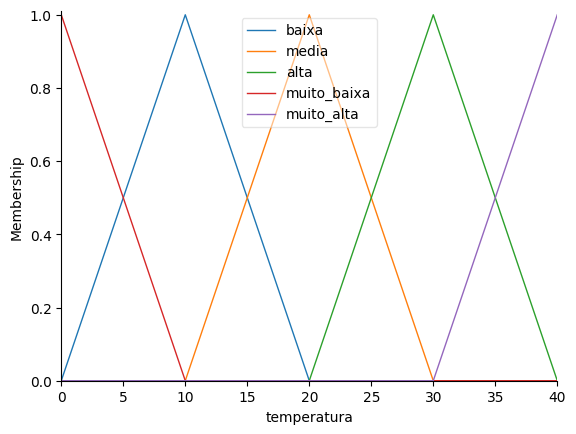

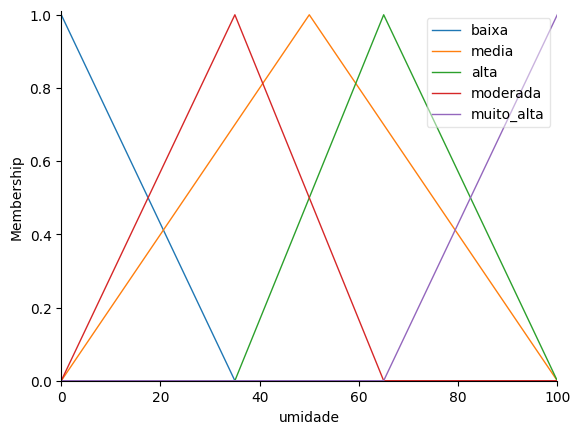

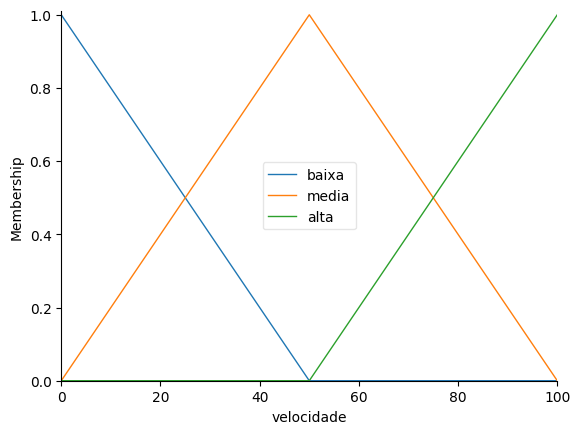

In [ ]:
temperatura.view()
umidade.view()
velocidade.view()
plt.show()

In [ ]:
regras = [
ctrl.Rule(temperatura['muito_baixa'] & umidade['baixa'], velocidade['baixa']),
ctrl.Rule(temperatura['muito_baixa'] & umidade['moderada'], velocidade['baixa']),
ctrl.Rule(temperatura['muito_baixa'] & umidade['alta'], velocidade['baixa']),
ctrl.Rule(temperatura['muito_baixa'] & umidade['muito_alta'], velocidade['baixa']),
ctrl.Rule(temperatura['baixa'] & umidade['baixa'], velocidade['baixa']),
ctrl.Rule(temperatura['baixa'] & umidade['moderada'], velocidade['baixa']),
ctrl.Rule(temperatura['baixa'] & umidade['alta'], velocidade['media']),
ctrl.Rule(temperatura['baixa'] & umidade['muito_alta'], velocidade['media']),
ctrl.Rule(temperatura['media'] & umidade['baixa'], velocidade['media']),
 ctrl.Rule(temperatura['media'] & umidade['moderada'], velocidade['media']),
 ctrl.Rule(temperatura['media'] & umidade['alta'], velocidade['media']),
 ctrl.Rule(temperatura['media'] & umidade['muito_alta'], velocidade['alta']),
 ctrl.Rule(temperatura['alta'] & umidade['baixa'], velocidade['media']),
 ctrl.Rule(temperatura['alta'] & umidade['moderada'], velocidade['alta']),
 ctrl.Rule(temperatura['alta'] & umidade['alta'], velocidade['alta']),
 ctrl.Rule(temperatura['alta'] & umidade['muito_alta'], velocidade['alta']),
 ctrl.Rule(temperatura['muito_alta'] & umidade['baixa'], velocidade['alta']),
 ctrl.Rule(temperatura['muito_alta'] & umidade['moderada'], velocidade['alta']),
 ctrl.Rule(temperatura['muito_alta'] & umidade['alta'], velocidade['alta']),
 ctrl.Rule(temperatura['muito_alta'] & umidade['muito_alta'], velocidade['alta'])
]

In [ ]:
sistema_controle = ctrl.ControlSystem(regras)

In [ ]:
sistema = ctrl.ControlSystemSimulation(sistema_controle)

In [ ]:
sistema.input['temperatura'] = 30
sistema.input['umidade'] = 70
sistema.compute()

83.03571428571429


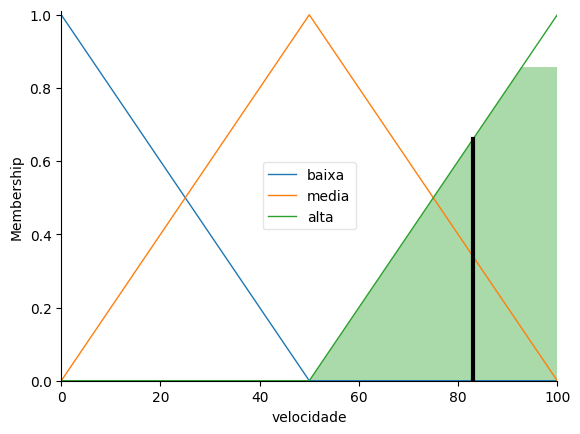

In [ ]:
print(sistema.output['velocidade'])
velocidade.view(sim = sistema)